Configuration:
  Input Image: /Users/domopapp/Documents/bachelor/playground/skraafoto_image.tif
  Output Image: output_detection/detected_cars_output.jpg
  Tile Size: 300x300
  Overlap: 50 pixels
  Step Size: 250 pixels
  YOLO Model: yolov8n.pt
  Confidence Threshold: 0.3
  NMS Threshold: 0.4
  Target Class: car
  Save Example Tiles: True
  Max Example Tiles: 10
  Example Tiles Dir: output_detection/example_tiles
Loading YOLOv8 model: yolov8n.pt...
Model loaded successfully.
Found target class 'car' with ID: 2
Loading image: /Users/domopapp/Documents/bachelor/playground/skraafoto_image.tif...
Image loaded. Dimensions: 14144x10560
Starting detection on tiles...


Processing Tiles:   0%|          | 0/2451 [00:00<?, ?it/s]

Processed 2451 tiles in 99.66 seconds.
Raw detections: 848
Saved 10 example tiles to 'output_detection/example_tiles'.
Applying NMS...
NMS complete. Final detections: 709
Drawing bounding boxes...
Saving image to: output_detection/detected_cars_output.jpg


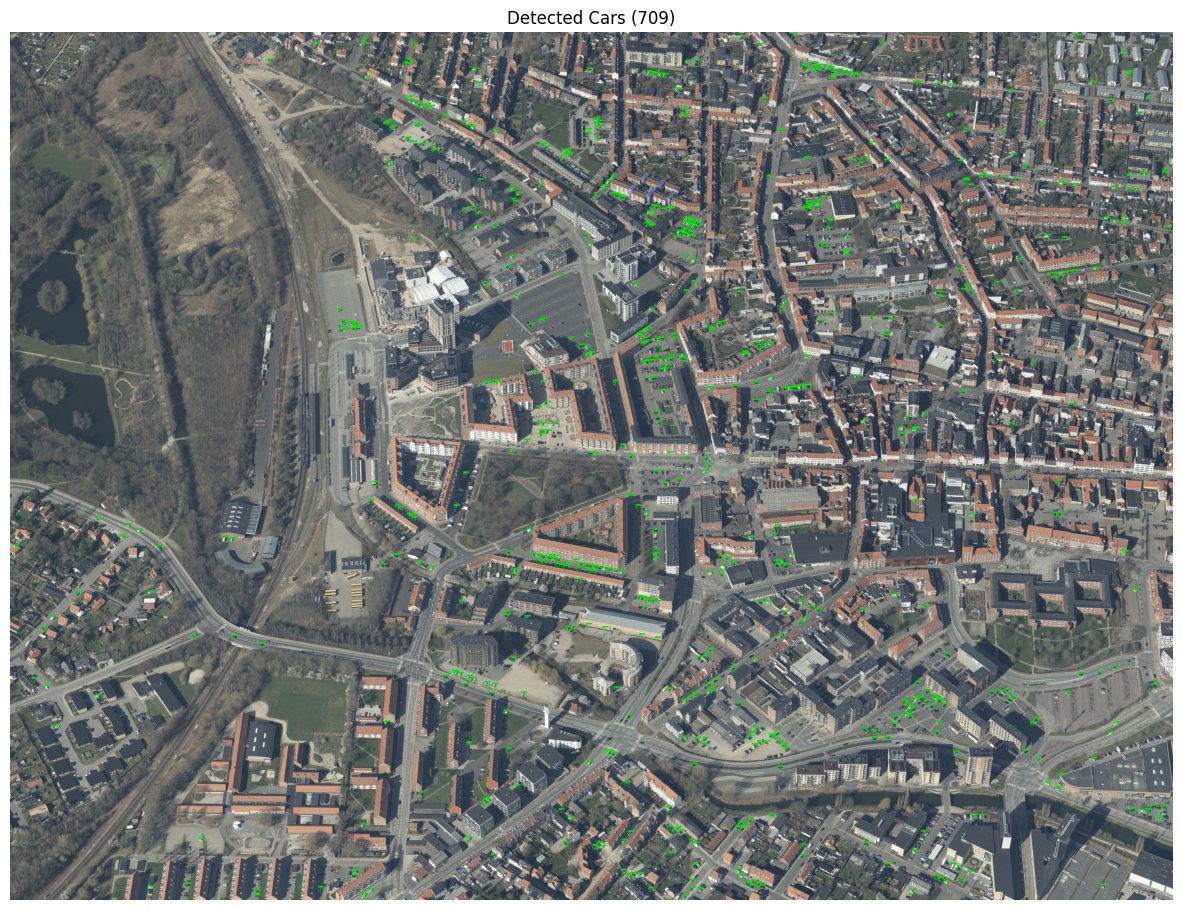

--- Detection Complete ---
Total cars detected: 709
Image saved at: output_detection/detected_cars_output.jpg
Example tiles saved in: output_detection/example_tiles


In [2]:
# %% [markdown]
# # Car Detection in Aerial Images using YOLOv8 and Tiling

# %% [markdown]
# ## 1. Setup

# %%
# !pip install ultralytics opencv-python matplotlib numpy tqdm

# %%
import cv2
import numpy as np
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import time

# %% [markdown]
# ## 2. Configuration

# %%
IMAGE_PATH = '/Users/domopapp/Documents/bachelor/playground/skraafoto_image.tif' # <-- Update if needed
OUTPUT_DIR = 'output_detection'
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUT_IMAGE_NAME = 'detected_cars_output.jpg'
OUTPUT_IMAGE_PATH = os.path.join(OUTPUT_DIR, OUTPUT_IMAGE_NAME)

# --- Example Tile Saving Config ---
SAVE_EXAMPLE_TILES = True
MAX_EXAMPLE_TILES = 10
EXAMPLE_TILES_DIR = os.path.join(OUTPUT_DIR, 'example_tiles')
if SAVE_EXAMPLE_TILES:
    os.makedirs(EXAMPLE_TILES_DIR, exist_ok=True)
# --- End Example Tile Saving ---

TILE_SIZE = 300
OVERLAP = 50

MODEL_NAME = 'yolov8n.pt'

CONFIDENCE_THRESHOLD = 0.3
NMS_THRESHOLD = 0.4
TARGET_CLASS_NAME = 'car'

step = TILE_SIZE - OVERLAP
if step <= 0:
    raise ValueError("Overlap must be smaller than Tile Size.")

print(f"Configuration:")
print(f"  Input Image: {IMAGE_PATH}")
print(f"  Output Image: {OUTPUT_IMAGE_PATH}")
print(f"  Tile Size: {TILE_SIZE}x{TILE_SIZE}")
print(f"  Overlap: {OVERLAP} pixels")
print(f"  Step Size: {step} pixels")
print(f"  YOLO Model: {MODEL_NAME}")
print(f"  Confidence Threshold: {CONFIDENCE_THRESHOLD}")
print(f"  NMS Threshold: {NMS_THRESHOLD}")
print(f"  Target Class: {TARGET_CLASS_NAME}")
print(f"  Save Example Tiles: {SAVE_EXAMPLE_TILES}")
if SAVE_EXAMPLE_TILES:
    print(f"  Max Example Tiles: {MAX_EXAMPLE_TILES}")
    print(f"  Example Tiles Dir: {EXAMPLE_TILES_DIR}")


# %% [markdown]
# ## 3. Load YOLOv8 Model

# %%
print(f"Loading YOLOv8 model: {MODEL_NAME}...")
try:
    model = YOLO(MODEL_NAME)
    print("Model loaded successfully.")
except Exception as e:
    print(f"Error loading model: {e}")
    raise

class_names = model.names
try:
    car_class_id = [k for k, v in class_names.items() if v.lower() == TARGET_CLASS_NAME.lower()][0]
    print(f"Found target class '{TARGET_CLASS_NAME}' with ID: {car_class_id}")
except IndexError:
    print(f"Class '{TARGET_CLASS_NAME}' not found in the model.")
    raise

# %% [markdown]
# ## 4. Load Image

# %%
print(f"Loading image: {IMAGE_PATH}...")
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Image not found at: {IMAGE_PATH}")

original_image = cv2.imread(IMAGE_PATH)
if original_image is None:
    raise IOError(f"Could not read image: {IMAGE_PATH}")

h, w = original_image.shape[:2]
print(f"Image loaded. Dimensions: {w}x{h}")

output_image = original_image.copy()

# %% [markdown]
# ## 5. Tiling and Detection

# %%
all_detections = []
tile_coords = []
saved_tile_count = 0 # Counter for saved example tiles

print("Starting detection on tiles...")
start_time = time.time()

num_tiles_y = len(range(0, h, step))
num_tiles_x = len(range(0, w, step))
total_tiles = num_tiles_y * num_tiles_x

with tqdm(total=total_tiles, desc="Processing Tiles") as pbar:
    for y in range(0, h, step):
        for x in range(0, w, step):
            y1, x1 = y, x
            y2 = min(y + TILE_SIZE, h)
            x2 = min(x + TILE_SIZE, w)

            tile = original_image[y1:y2, x1:x2]
            if tile.shape[0] < OVERLAP or tile.shape[1] < OVERLAP:
                 pbar.update(1)
                 continue

            tile_coords.append((x1, y1, x2, y2))

            results = model.predict(source=tile, conf=CONFIDENCE_THRESHOLD, classes=[car_class_id], verbose=False)
            detections_on_tile = results[0].boxes.data.cpu().numpy() # Detections for this tile

            # --- Save Example Tile ---
            if SAVE_EXAMPLE_TILES and len(detections_on_tile) > 0 and saved_tile_count < MAX_EXAMPLE_TILES:
                tile_to_save = tile.copy()
                for det_tile in detections_on_tile:
                    tx1, ty1, tx2, ty2, tconf, _ = det_tile
                    cv2.rectangle(tile_to_save, (int(tx1), int(ty1)), (int(tx2), int(ty2)), (255, 0, 0), 1) # Blue box
                    label = f"{tconf:.2f}"
                    cv2.putText(tile_to_save, label, (int(tx1), int(ty1) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

                tile_filename = f"example_tile_{saved_tile_count+1}_x{x1}_y{y1}.jpg"
                tile_save_path = os.path.join(EXAMPLE_TILES_DIR, tile_filename)
                try:
                    cv2.imwrite(tile_save_path, tile_to_save)
                except Exception as e:
                    print(f"Warning: Could not save example tile {tile_filename}. Error: {e}")
                saved_tile_count += 1
            # --- End Save Example Tile ---

            # Add detections to global list (original image coordinates)
            for det in detections_on_tile:
                x1_tile, y1_tile, x2_tile, y2_tile, conf, class_id = det
                x1_orig = int(x1 + x1_tile)
                y1_orig = int(y1 + y1_tile)
                x2_orig = int(x1 + x2_tile)
                y2_orig = int(y1 + y2_tile)
                all_detections.append([x1_orig, y1_orig, x2_orig, y2_orig, conf])

            pbar.update(1)

end_time = time.time()
print(f"Processed {total_tiles} tiles in {end_time - start_time:.2f} seconds.")
print(f"Raw detections: {len(all_detections)}")
if SAVE_EXAMPLE_TILES:
    print(f"Saved {saved_tile_count} example tiles to '{EXAMPLE_TILES_DIR}'.")


# %% [markdown]
# ## 6. Non-Maximum Suppression

# %%
print("Applying NMS...")

if not all_detections:
    print("No detections to process.")
    final_detections = []
else:
    boxes_for_nms = []
    confidences_for_nms = []
    for x1, y1, x2, y2, conf in all_detections:
        boxes_for_nms.append([x1, y1, x2 - x1, y2 - y1]) # NMS needs x, y, width, height
        confidences_for_nms.append(float(conf))

    indices = cv2.dnn.NMSBoxes(boxes_for_nms, confidences_for_nms, CONFIDENCE_THRESHOLD, NMS_THRESHOLD)

    final_detections = []
    if len(indices) > 0:
        # Handle potential nested list output from NMSBoxes
        if isinstance(indices[0], (list, np.ndarray)):
             indices = indices.flatten()
        for i in indices:
            final_detections.append(all_detections[i])

    print(f"NMS complete. Final detections: {len(final_detections)}")

# %% [markdown]
# ## 7. Visualization

# %%
print("Drawing bounding boxes...")

for x1, y1, x2, y2, conf in final_detections:
    x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)
    # Draw box on the main output image (Green)
    cv2.rectangle(output_image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    # Add label with confidence
    label = f"{TARGET_CLASS_NAME}: {conf:.2f}"
    label_size, base_line = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    y1_label = max(y1, label_size[1] + 10)
    cv2.rectangle(output_image, (x1, y1_label - label_size[1] - base_line), (x1 + label_size[0], y1_label), (0, 255, 0), cv2.FILLED)
    cv2.putText(output_image, label, (x1, y1_label - base_line), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1) # Black text

print(f"Saving image to: {OUTPUT_IMAGE_PATH}")
cv2.imwrite(OUTPUT_IMAGE_PATH, output_image)

# Display final result
plt.figure(figsize=(15, 15))
plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
plt.title(f'Detected Cars ({len(final_detections)})')
plt.axis('off')
plt.show()

print("--- Detection Complete ---")
print(f"Total cars detected: {len(final_detections)}")
print(f"Image saved at: {OUTPUT_IMAGE_PATH}")
if SAVE_EXAMPLE_TILES:
    print(f"Example tiles saved in: {EXAMPLE_TILES_DIR}")
